# Baseline experiments trên Colab T4

Notebook này điều phối ba baseline **ResNet-50 → DenseNet-121 → ViT-B/16** bằng `scripts/train.py`. Training logic vẫn nằm trong source code của repository.

## Trước khi chạy

1. Trong VS Code, chọn kernel **Colab** và cấp một runtime có GPU T4.
2. Đặt archive dữ liệu tại `MyDrive/DATH_CXR/datasets/consensus_v1_224.zip`.
3. Archive phải chứa folder gốc `consensus_v1_224/` với `images/`, `masks/`, `splits/`, `manifest.csv` và `metadata.json`.
4. Checkpoint và log sẽ được giữ trên Google Drive để có thể resume sau khi runtime bị ngắt.

> Notebook không commit hoặc push source code hay artifact lên GitHub.


In [1]:
from pathlib import Path

REPO_URL = "https://github.com/HuyDuongQuoc/DATH-HK261-explainable-cxr.git"
REPO_BRANCH = "feature/02-experiment-notebook"
REPO_DIR = Path("/content/DATH-HK261-explainable-cxr")

DRIVE_MOUNT = Path("/content/drive")
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive" / "DATH_CXR"
DATA_ARCHIVE = DRIVE_ROOT / "datasets" / "consensus_v1_224.zip"
CHECKPOINT_ROOT = DRIVE_ROOT / "checkpoints"
RUN_LOG_ROOT = DRIVE_ROOT / "run_logs"
LOCAL_DATA_ROOT = Path("/content/datasets")
PROCESSED_ROOT = LOCAL_DATA_ROOT / "consensus_v1_224"
RUNTIME_CONFIG_ROOT = Path("/content/runtime_configs")
EXPORT_PATH = Path("/content/exports/02_experiment_results.zip")

REQUIRE_T4 = True
EXPECTED_IMAGES = 15_000
EXPECTED_MASKS = 15_000
EXPECTED_TRAIN_ROWS = 10_500
EXPECTED_VAL_ROWS = 2_250
EXPECTED_TEST_ROWS = 2_250

EXPERIMENTS = [
    {
        "run_name": "resnet50_baseline_s701515_seed42_amp",
        "model_name": "resnet50",
        "config": "configs/resnet50_baseline.yaml",
    },
    {
        "run_name": "densenet121_baseline_s701515_seed42_amp",
        "model_name": "densenet121",
        "config": "configs/densenet121_baseline.yaml",
    },
    {
        "run_name": "vit_baseline_s701515_seed42_amp",
        "model_name": "vit_b_16",
        "config": "configs/vit_baseline.yaml",
    },
]

print("Experiments:", [item["run_name"] for item in EXPERIMENTS])
print("Data archive:", DATA_ARCHIVE)
print("Local processed dataset:", PROCESSED_ROOT)
print("Export path:", EXPORT_PATH)


Experiments: ['resnet50_baseline_s701515_seed42_amp', 'densenet121_baseline_s701515_seed42_amp', 'vit_baseline_s701515_seed42_amp']
Data archive: /content/drive/MyDrive/DATH_CXR/datasets/consensus_v1_224.zip
Local processed dataset: /content/datasets/consensus_v1_224
Export path: /content/exports/02_experiment_results.zip


## 1. Mount Google Drive

Drive là nơi lưu archive dữ liệu, checkpoint và run log bền vững.


In [2]:
from google.colab import drive

drive.mount(str(DRIVE_MOUNT), force_remount=False)

if not DATA_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy archive dữ liệu: {DATA_ARCHIVE}. "
        "Hãy upload consensus_v1_224.zip lên đúng vị trí rồi chạy lại cell."
    )

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Drive is ready:", DRIVE_ROOT)


Mounted at /content/drive
Drive is ready: /content/drive/MyDrive/DATH_CXR


## 2. Clone hoặc cập nhật source từ `main`

PAT chỉ được giữ trong memory của kernel. Để trống nếu repository có thể clone công khai. Notebook không ghi token vào file, output hoặc Git config.


In [3]:
import base64
import os
import subprocess
import sys
from getpass import getpass

github_token = getpass("GitHub PAT (để trống nếu repo public): " ).strip()

git_auth_env = os.environ.copy()
if github_token:
    auth = base64.b64encode(
        f"x-access-token:{github_token}".encode("utf-8")
    ).decode("ascii")
    git_auth_env.update({
        "GIT_CONFIG_COUNT": "1",
        "GIT_CONFIG_KEY_0": "http.extraHeader",
        "GIT_CONFIG_VALUE_0": f"Authorization: Basic {auth}",
    })

def run_git(arguments, cwd=None):
    command = ["git", *arguments]
    return subprocess.run(command, cwd=cwd, env=git_auth_env, check=True)

if REPO_DIR.exists():
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(
            f"{REPO_DIR} đã tồn tại nhưng không phải Git repository. "
            "Hãy xóa folder này hoặc khởi tạo runtime mới."
        )
    run_git(["fetch", "origin", REPO_BRANCH], cwd=REPO_DIR)
    run_git(["checkout", REPO_BRANCH], cwd=REPO_DIR)
    run_git(["pull", "--ff-only", "origin", REPO_BRANCH], cwd=REPO_DIR)
else:
    run_git([
        "clone",
        "--branch", REPO_BRANCH,
        "--single-branch",
        REPO_URL,
        str(REPO_DIR),
    ])

repo_path = str(REPO_DIR.resolve())
os.chdir(REPO_DIR)
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

github_token = None
auth = None
git_auth_env = None

commit_sha = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_DIR,
    check=True,
    capture_output=True,
    text=True,
).stdout.strip()
print("Repository:", REPO_DIR)
print("Branch:", REPO_BRANCH)
print("Commit:", commit_sha)


GitHub PAT (để trống nếu repo public): ··········
Repository: /content/DATH-HK261-explainable-cxr
Branch: feature/02-experiment-notebook
Commit: d7d540b2cad0c9390bf938528154c7a383d9b662


## 3. Cài dependencies và xác nhận T4

Không import PyTorch trước khi cài requirements để tránh giữ phiên bản cũ trong kernel.


In [4]:
import sys

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-r", str(REPO_DIR / "requirements-common.txt")],
    check=True,
)
print("Dependencies installed.")


Dependencies installed.


In [5]:
import torch
import torchvision

nvidia_smi = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
    check=False,
    capture_output=True,
    text=True,
)
if nvidia_smi.returncode != 0:
    raise RuntimeError(
        "Không gọi được nvidia-smi. Hãy tạo Colab server có GPU trong VS Code."
    )

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch không phát hiện CUDA. Không bắt đầu training trên CPU.")
if torch.version.cuda is None:
    raise RuntimeError("PyTorch hiện tại không được build với CUDA.")

gpu_name = torch.cuda.get_device_name(0)
if REQUIRE_T4 and "T4" not in gpu_name.upper():
    raise RuntimeError(
        f"Runtime đang dùng {gpu_name}, không phải Tesla T4. "
        "Hãy remove server và provision một Colab server T4."
    )

try:
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        _amp_probe = torch.ones(8, 8, device="cuda") @ torch.ones(8, 8, device="cuda")
    if not torch.isfinite(_amp_probe).all():
        raise RuntimeError("AMP probe produced non-finite values")
    del _amp_probe
except Exception as error:
    raise RuntimeError("Runtime T4 không hỗ trợ CUDA autocast FP16.") from error

print(nvidia_smi.stdout.strip())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("AMP FP16 probe: OK")


Tesla T4, 580.82.07, 15360 MiB
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
AMP FP16 probe: OK


## 4. Giải nén và kiểm tra processed dataset

Archive nguồn được đọc từ Google Drive. Dataset được giải nén một lần sang `/content/datasets` để train trên SSD local của Colab; repository chỉ chứa code. Cell này idempotent trong cùng runtime.


In [6]:
import shutil
import tempfile
import json
import zipfile

import pandas as pd

from src.data.splitting import assignment_sha256

def dataset_summary(root):
    required = [
        root / "images",
        root / "masks",
        root / "splits" / "train.csv",
        root / "splits" / "val.csv",
        root / "splits" / "test.csv",
        root / "splits" / "summary.csv",
        root / "splits" / "split_metadata.json",
        root / "manifest.csv",
        root / "metadata.json",
    ]
    if not all(path.exists() for path in required):
        return None

    tables = {
        name: pd.read_csv(root / "splits" / f"{name}.csv")
        for name in ("train", "val", "test")
    }
    id_sets = {name: set(table["image_id"].astype(str)) for name, table in tables.items()}
    if not id_sets["train"].isdisjoint(id_sets["val"]):
        raise ValueError("Train/validation overlap")
    if not id_sets["train"].isdisjoint(id_sets["test"]):
        raise ValueError("Train/test overlap")
    if not id_sets["val"].isdisjoint(id_sets["test"]):
        raise ValueError("Validation/test overlap")
    manifest_ids = set(pd.read_csv(root / "manifest.csv")["image_id"].astype(str))
    if set().union(*id_sets.values()) != manifest_ids:
        raise ValueError("Split IDs do not cover the processed manifest")
    split_metadata = json.loads(
        (root / "splits" / "split_metadata.json").read_text(encoding="utf-8")
    )
    calculated_assignment = assignment_sha256(tables)
    if split_metadata.get("assignment_sha256") != calculated_assignment:
        raise ValueError("Split assignment fingerprint mismatch")

    return {
        "images": sum(1 for _ in (root / "images").glob("*.png")),
        "masks": sum(1 for _ in (root / "masks").glob("*.npz")),
        "train_rows": len(pd.read_csv(root / "splits" / "train.csv")),
        "val_rows": len(pd.read_csv(root / "splits" / "val.csv")),
        "test_rows": len(pd.read_csv(root / "splits" / "test.csv")),
        "split_assignment_sha256": calculated_assignment,
    }

def validate_dataset(root):
    summary = dataset_summary(root)
    expected = {
        "images": EXPECTED_IMAGES,
        "masks": EXPECTED_MASKS,
        "train_rows": EXPECTED_TRAIN_ROWS,
        "val_rows": EXPECTED_VAL_ROWS,
        "test_rows": EXPECTED_TEST_ROWS,
    }
    actual_counts = {key: summary[key] for key in expected}
    if actual_counts != expected:
        raise ValueError(
            f"Processed dataset không đúng contract. Expected={expected}, actual={actual_counts}"
        )
    return summary

def safe_extract_zip(archive_path, destination):
    destination = destination.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            try:
                target.relative_to(destination)
            except ValueError as error:
                raise ValueError(f"Unsafe ZIP member: {member.filename}") from error
        archive.extractall(destination)

existing_summary = dataset_summary(PROCESSED_ROOT)
if existing_summary is not None:
    validate_dataset(PROCESSED_ROOT)
    print("Dataset đã tồn tại và hợp lệ; bỏ qua giải nén.")
else:
    if PROCESSED_ROOT.exists():
        raise RuntimeError(
            f"{PROCESSED_ROOT} đã tồn tại nhưng không đầy đủ. "
            "Hãy khởi tạo runtime mới để tránh ghi đè dữ liệu không rõ nguồn gốc."
        )

    temporary_root = Path(tempfile.mkdtemp(prefix="cxr-extract-", dir="/content"))
    try:
        safe_extract_zip(DATA_ARCHIVE, temporary_root)
        extracted_root = temporary_root / "consensus_v1_224"
        validate_dataset(extracted_root)
        PROCESSED_ROOT.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(extracted_root), str(PROCESSED_ROOT))
    finally:
        shutil.rmtree(temporary_root, ignore_errors=True)

summary = validate_dataset(PROCESSED_ROOT)
print("Processed dataset ready:", PROCESSED_ROOT)
print(summary)


Processed dataset ready: /content/datasets/consensus_v1_224
{'images': 15000, 'masks': 15000, 'train_rows': 10500, 'val_rows': 2250, 'test_rows': 2250, 'split_assignment_sha256': '86741f2444ddec624d33632b1b0ed87ead51255a22e02dce6b8fc9af3fb83af6'}


## 5. Training tuần tự và tự động resume

Mỗi epoch đều ghi `last.pt` lên Drive. Khi chạy lại notebook, experiment chưa hoàn tất sẽ resume; experiment đã đủ epoch hoặc đã early-stop sẽ được bỏ qua.


In [7]:
import os
import yaml

from src.utils.config import load_config

def build_runtime_config(experiment):
    source_config_path = REPO_DIR / experiment["config"]
    config = load_config(source_config_path)
    config["data"]["processed_root"] = str(PROCESSED_ROOT)

    runtime_dir = RUNTIME_CONFIG_ROOT / experiment["run_name"]
    runtime_dir.mkdir(parents=True, exist_ok=True)
    runtime_config_path = runtime_dir / "default.yaml"
    runtime_config_path.write_text(
        yaml.safe_dump(config, sort_keys=False, allow_unicode=True),
        encoding="utf-8",
    )
    return runtime_config_path, source_config_path, config

def inspect_run(experiment):
    config_path, source_config_path, config = build_runtime_config(experiment)
    checkpoint_dir = CHECKPOINT_ROOT / experiment["run_name"]
    result_dir = RUN_LOG_ROOT / experiment["run_name"]
    last_checkpoint = checkpoint_dir / "last.pt"
    best_checkpoint = checkpoint_dir / "best.pt"

    state = {
        "config_path": config_path,
        "source_config_path": source_config_path,
        "config": config,
        "checkpoint_dir": checkpoint_dir,
        "result_dir": result_dir,
        "last_checkpoint": last_checkpoint,
        "resume": False,
        "complete": False,
    }

    if best_checkpoint.is_file() and not last_checkpoint.is_file():
        raise RuntimeError(
            f"Phát hiện best.pt nhưng thiếu last.pt trong {checkpoint_dir}. "
            "Không bắt đầu run mới để tránh ghi đè artifact cũ."
        )

    if last_checkpoint.is_file():
        checkpoint = torch.load(last_checkpoint, map_location="cpu", weights_only=False)
        if checkpoint.get("model_name") != experiment["model_name"]:
            raise ValueError(f"Checkpoint backbone mismatch: {last_checkpoint}")
        if checkpoint.get("findings") != config["data"]["target_findings"]:
            raise ValueError(f"Checkpoint class order mismatch: {last_checkpoint}")
        if checkpoint.get("split_assignment_sha256") != summary["split_assignment_sha256"]:
            raise ValueError(f"Checkpoint split fingerprint mismatch: {last_checkpoint}")
        if checkpoint.get("amp_enabled") is not True:
            raise ValueError(f"Checkpoint không thuộc AMP protocol: {last_checkpoint}")

        completed_epochs = int(checkpoint["epoch"]) + 1
        reached_limit = completed_epochs >= int(config["training"]["epochs"])
        early_stopped = int(checkpoint["bad_epochs"]) >= int(
            config["training"]["patience"]
        )
        state["complete"] = reached_limit or early_stopped
        state["resume"] = not state["complete"]
        state["completed_epochs"] = completed_epochs

    return state

def train_experiment(experiment):
    state = inspect_run(experiment)
    run_name = experiment["run_name"]
    state["checkpoint_dir"].mkdir(parents=True, exist_ok=True)
    state["result_dir"].mkdir(parents=True, exist_ok=True)

    if state["complete"]:
        print(f"[{run_name}] đã hoàn tất; bỏ qua training.")
    else:
        command = [
            sys.executable,
            str(REPO_DIR / "scripts" / "train.py"),
            "--config", str(state["config_path"]),
            "--checkpoint-dir", str(state["checkpoint_dir"]),
            "--result-dir", str(state["result_dir"]),
        ]
        if state["resume"]:
            command.extend(["--resume", str(state["last_checkpoint"])])
            print(f"[{run_name}] resume từ {state['last_checkpoint']}")
        else:
            print(f"[{run_name}] bắt đầu run mới")

        training_env = os.environ.copy()
        current_pythonpath = training_env.get("PYTHONPATH")
        training_env["PYTHONPATH"] = (
            str(REPO_DIR)
            if not current_pythonpath
            else str(REPO_DIR) + os.pathsep + current_pythonpath
        )
        subprocess.run(
            command,
            cwd=REPO_DIR,
            env=training_env,
            check=True,
        )

    best_checkpoint = state["checkpoint_dir"] / "best.pt"
    if not best_checkpoint.is_file():
        raise FileNotFoundError(f"Không tìm thấy best checkpoint: {best_checkpoint}")
    return inspect_run(experiment)


In [8]:
import json

def load_best_metrics(experiment):
    state = inspect_run(experiment)
    best_checkpoint_path = state["checkpoint_dir"] / "best.pt"
    metrics_path = state["result_dir"] / "best_val_metrics.json"
    if not best_checkpoint_path.is_file():
        raise FileNotFoundError(best_checkpoint_path)
    if not metrics_path.is_file():
        raise FileNotFoundError(metrics_path)

    checkpoint = torch.load(best_checkpoint_path, map_location="cpu", weights_only=False)
    findings = state["config"]["data"]["target_findings"]
    if checkpoint.get("model_name") != experiment["model_name"]:
        raise ValueError(f"Best checkpoint backbone mismatch: {best_checkpoint_path}")
    if checkpoint.get("findings") != findings:
        raise ValueError(f"Best checkpoint class order mismatch: {best_checkpoint_path}")
    if checkpoint.get("split_assignment_sha256") != summary["split_assignment_sha256"]:
        raise ValueError(f"Best checkpoint split fingerprint mismatch: {best_checkpoint_path}")
    if checkpoint.get("amp_enabled") is not True:
        raise ValueError(f"Best checkpoint không thuộc AMP protocol: {best_checkpoint_path}")

    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    if metrics.get("amp_enabled") is not True:
        raise ValueError(f"Best metrics không thuộc AMP protocol: {metrics_path}")
    if metrics.get("split_assignment_sha256") != summary["split_assignment_sha256"]:
        raise ValueError(f"Best metrics split fingerprint mismatch: {metrics_path}")
    print(
        f"[{experiment['run_name']}] best epoch={metrics['checkpoint_epoch']}, "
        f"macro-AUROC={metrics['macro_auroc']:.4f}"
    )
    return metrics

best_metrics_by_run = {}
for experiment_index, experiment in enumerate(EXPERIMENTS, start=1):
    print(f"[{experiment_index}/{len(EXPERIMENTS)}] {experiment['run_name']}")
    train_experiment(experiment)
    best_metrics_by_run[experiment["run_name"]] = load_best_metrics(experiment)

print("All experiments completed and evaluated.")


[1/3] resnet50_baseline_s701515_seed42_amp
[resnet50_baseline_s701515_seed42_amp] đã hoàn tất; bỏ qua training.
[resnet50_baseline_s701515_seed42_amp] best epoch=7, macro-AUROC=0.9538
[2/3] densenet121_baseline_s701515_seed42_amp
[densenet121_baseline_s701515_seed42_amp] đã hoàn tất; bỏ qua training.
[densenet121_baseline_s701515_seed42_amp] best epoch=7, macro-AUROC=0.9577
[3/3] vit_baseline_s701515_seed42_amp
[vit_baseline_s701515_seed42_amp] resume từ /content/drive/MyDrive/DATH_CXR/checkpoints/vit_baseline_s701515_seed42_amp/last.pt
[vit_baseline_s701515_seed42_amp] best epoch=23, macro-AUROC=0.8622
All experiments completed and evaluated.


## 6. Tổng hợp và đóng gói kết quả

ZIP chỉ chứa metrics, config và metadata tái lập. Checkpoint `.pt` không được đưa vào gói tải về.


In [9]:
import hashlib
from datetime import datetime, timezone

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

summary_rows = []
for experiment in EXPERIMENTS:
    run_name = experiment["run_name"]
    result_dir = RUN_LOG_ROOT / run_name
    history_path = result_dir / "history.csv"
    metrics_path = result_dir / "best_val_metrics.json"
    if not history_path.is_file() or not metrics_path.is_file():
        raise FileNotFoundError(f"Thiếu artifact để export cho {run_name}")

    history = pd.read_csv(history_path)
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    summary_rows.append({
        "experiment": run_name,
        "model": experiment["model_name"],
        "best_epoch": int(metrics["checkpoint_epoch"]),
        "epochs_completed": int(len(history)),
        "val_macro_auroc": float(metrics["macro_auroc"]),
        "val_macro_average_precision": float(metrics["macro_average_precision"]),
        "val_macro_f1": float(metrics["macro_f1"]),
        "total_train_seconds": float(history["train_seconds"].sum()),
        "total_val_seconds": float(history["val_seconds"].sum()),
        "mean_train_images_per_second": float(history["train_images_per_second"].mean()),
        "mean_val_images_per_second": float(history["val_images_per_second"].mean()),
        "peak_gpu_memory_gb": float(history["peak_gpu_memory_gb"].max()),
    })

source_status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_DIR,
    check=True,
    capture_output=True,
    text=True,
).stdout.splitlines()
default_config = load_config(REPO_DIR / "configs" / "default.yaml")
manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "repository_url": REPO_URL,
    "repository_branch": REPO_BRANCH,
    "git_commit": commit_sha,
    "git_worktree_status": source_status,
    "gpu": gpu_name,
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_version": torch.version.cuda,
    "amp_enabled": bool(default_config["training"]["use_amp"]),
    "data_loader": {
        "batch_size": int(default_config["training"]["batch_size"]),
        "num_workers": int(default_config["training"]["num_workers"]),
        "persistent_workers": bool(default_config["training"]["persistent_workers"]),
        "prefetch_factor": int(default_config["training"]["prefetch_factor"]),
    },
    "seed": int(default_config["seed"]),
    "data_archive": str(DATA_ARCHIVE),
    "data_archive_sha256": sha256_file(DATA_ARCHIVE),
    "data_archive_storage": "google_drive",
    "processed_root": str(PROCESSED_ROOT),
    "processed_storage": "colab_local_ssd",
    "processed_dataset": summary,
    "split_assignment_sha256": summary["split_assignment_sha256"],
    "experiments": [item["run_name"] for item in EXPERIMENTS],
    "checkpoint_root": str(CHECKPOINT_ROOT),
    "checkpoint_included_in_export": False,
}

staging_root = Path(tempfile.mkdtemp(prefix="cxr-export-", dir="/content"))
metrics_root = staging_root / "outputs" / "metrics"
metrics_root.mkdir(parents=True, exist_ok=True)

required_files = [
    "config.json",
    "history.csv",
    "latest_val_metrics.json",
    "best_val_metrics.json",
]
for experiment in EXPERIMENTS:
    run_name = experiment["run_name"]
    source_dir = RUN_LOG_ROOT / run_name
    destination_dir = metrics_root / run_name
    destination_dir.mkdir(parents=True, exist_ok=True)
    for filename in required_files:
        source_file = source_dir / filename
        if not source_file.is_file():
            raise FileNotFoundError(f"Thiếu artifact: {source_file}")
        shutil.copy2(source_file, destination_dir / filename)

pd.DataFrame(summary_rows).to_csv(metrics_root / "baseline_summary.csv", index=False)
(metrics_root / "experiment_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

EXPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
if EXPORT_PATH.exists():
    EXPORT_PATH.unlink()
shutil.make_archive(
    str(EXPORT_PATH.with_suffix("")),
    "zip",
    root_dir=staging_root,
)

with zipfile.ZipFile(EXPORT_PATH) as archive:
    members = sorted(name for name in archive.namelist() if not name.endswith("/"))
if any(name.lower().endswith((".pt", ".pth", ".ckpt")) for name in members):
    raise RuntimeError("Export ZIP chứa checkpoint ngoài ý muốn")
for experiment in EXPERIMENTS:
    prefix = f"outputs/metrics/{experiment['run_name']}/"
    if not all(prefix + filename in members for filename in required_files):
        raise RuntimeError(f"Export ZIP thiếu artifact cho {experiment['run_name']}")

shutil.rmtree(staging_root, ignore_errors=True)
print(pd.DataFrame(summary_rows).to_string(index=False))
print("Export ready:", EXPORT_PATH)
print("Files in ZIP:", len(members))


                             experiment       model  best_epoch  epochs_completed  val_macro_auroc  val_macro_average_precision  val_macro_f1  total_train_seconds  total_val_seconds  mean_train_images_per_second  mean_val_images_per_second  peak_gpu_memory_gb
   resnet50_baseline_s701515_seed42_amp    resnet50           7                12         0.953809                     0.453067      0.368242           945.902112          91.174054                    133.319129                  296.146176            0.697496
densenet121_baseline_s701515_seed42_amp densenet121           7                12         0.957736                     0.477210      0.351527          1579.654163         134.835868                     79.902456                  200.319308            0.643340
        vit_baseline_s701515_seed42_amp    vit_b_16          23                28         0.862243                     0.191422      0.194231          4382.315110         253.633078                     67.142276         

## 7. Đánh giá 3 mô hình trên tập Test


In [10]:
import json
import os
import subprocess
import sys

import pandas as pd

TEST_THRESHOLD = 0.5
EXPECTED_TEST_IMAGES = 2_250

test_env = os.environ.copy()
current_pythonpath = test_env.get("PYTHONPATH")
test_env["PYTHONPATH"] = (
    str(REPO_DIR)
    if not current_pythonpath
    else str(REPO_DIR) + os.pathsep + current_pythonpath
)

test_summary_rows = []

for index, experiment in enumerate(EXPERIMENTS, start=1):
    run_name = experiment["run_name"]

    # Tạo lại resolved config với processed_root trên SSD Colab.
    config_path, _, _ = build_runtime_config(experiment)

    checkpoint_path = CHECKPOINT_ROOT / run_name / "best.pt"
    validation_metrics_path = (
        RUN_LOG_ROOT / run_name / "best_val_metrics.json"
    )
    test_output_dir = RUN_LOG_ROOT / run_name / "test"

    metrics_path = test_output_dir / "test_metrics.json"
    predictions_path = test_output_dir / "test_predictions.csv"
    metadata_path = test_output_dir / "evaluation_metadata.json"

    required_inputs = [
        checkpoint_path,
        validation_metrics_path,
        config_path,
    ]
    missing_inputs = [
        str(path) for path in required_inputs if not path.is_file()
    ]
    if missing_inputs:
        raise FileNotFoundError(
            f"[{run_name}] thiếu input: {missing_inputs}"
        )

    expected_outputs = [
        metrics_path,
        predictions_path,
        metadata_path,
    ]
    existing_outputs = [
        path for path in expected_outputs if path.exists()
    ]

    if len(existing_outputs) == len(expected_outputs):
        print(f"[{index}/3] {run_name}: test đã có, chỉ xác minh.")
    elif existing_outputs:
        raise RuntimeError(
            f"[{run_name}] test output không đầy đủ: "
            f"{[str(path) for path in existing_outputs]}"
        )
    else:
        print(f"[{index}/3] {run_name}: bắt đầu internal test.")

        subprocess.run(
            [
                sys.executable,
                "-m",
                "scripts.evaluate",
                "--config",
                str(config_path),
                "--checkpoint",
                str(checkpoint_path),
                "--output-dir",
                str(test_output_dir),
                "--split",
                "test",
                "--threshold",
                str(TEST_THRESHOLD),
            ],
            cwd=REPO_DIR,
            env=test_env,
            check=True,
        )

    metrics = json.loads(
        metrics_path.read_text(encoding="utf-8")
    )
    metadata = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )
    predictions = pd.read_csv(predictions_path)

    if metrics["split"] != "test":
        raise ValueError(f"[{run_name}] metrics không thuộc test split")

    if int(metrics["num_images"]) != EXPECTED_TEST_IMAGES:
        raise ValueError(
            f"[{run_name}] expected {EXPECTED_TEST_IMAGES} images, "
            f"received {metrics['num_images']}"
        )

    if len(predictions) != EXPECTED_TEST_IMAGES:
        raise ValueError(
            f"[{run_name}] prediction rows={len(predictions)}"
        )

    if (
        metadata["split_assignment_sha256"]
        != summary["split_assignment_sha256"]
    ):
        raise ValueError(
            f"[{run_name}] split fingerprint mismatch"
        )

    if float(metadata["threshold"]) != TEST_THRESHOLD:
        raise ValueError(f"[{run_name}] threshold mismatch")

    test_summary_rows.append(
        {
            "run_name": run_name,
            "model": experiment["model_name"],
            "checkpoint_epoch": metadata["checkpoint_epoch"],
            "macro_auroc": metrics["macro_auroc"],
            "macro_average_precision": (
                metrics["macro_average_precision"]
            ),
            "macro_precision": metrics["macro_precision"],
            "macro_recall": metrics["macro_recall"],
            "macro_f1": metrics["macro_f1"],
            "elapsed_seconds": metrics["elapsed_seconds"],
            "images_per_second": metrics["images_per_second"],
            "checkpoint_sha256": metadata["checkpoint_sha256"],
            "split_assignment_sha256": (
                metadata["split_assignment_sha256"]
            ),
        }
    )

test_summary = pd.DataFrame(test_summary_rows)

summary_path = RUN_LOG_ROOT / "test_baseline_summary.csv"
test_summary.to_csv(summary_path, index=False)

display(test_summary)
print("Test summary:", summary_path)

[1/3] resnet50_baseline_s701515_seed42_amp: bắt đầu internal test.
[2/3] densenet121_baseline_s701515_seed42_amp: bắt đầu internal test.
[3/3] vit_baseline_s701515_seed42_amp: bắt đầu internal test.


,run_name,model,checkpoint_epoch,macro_auroc,macro_average_precision,macro_precision,macro_recall,macro_f1,elapsed_seconds,images_per_second,checkpoint_sha256,split_assignment_sha256
0,resnet50_baseline_s701515_seed42_amp,resnet50,7,0.940063,0.447049,0.253198,0.783138,0.356370,11.575741,194.372012,ffc15c9a375f3cde986d8383774e6b85cf84da53cb4ebf...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...
1,densenet121_baseline_s701515_seed42_amp,densenet121,7,0.947552,0.484161,0.234985,0.850982,0.343410,13.790932,163.150690,1ab2b40823da8dcbdbc0c70c90bc0c63a259a8471ccb7d...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...
2,vit_baseline_s701515_seed42_amp,vit_b_16,23,0.845823,0.201541,0.118524,0.725017,0.188087,9.135629,246.288472,ca8a49c65bb24c175f7445c49ab23923c9028b61c6fa12...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...


Test summary: /content/drive/MyDrive/DATH_CXR/run_logs/test_baseline_summary.csv


# 8.Phân tích và tạo figure so sánh 3 mô hình


In [11]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    auc,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
)

EXPECTED_TEST_IMAGES = 2_250
EXPECTED_THRESHOLD = 0.5
EXPECTED_FINGERPRINT = summary["split_assignment_sha256"]

MODEL_LABELS = {
    "resnet50": "ResNet-50",
    "densenet121": "DenseNet-121",
    "vit_b_16": "ViT-B/16",
}
MODEL_ORDER = ["ResNet-50", "DenseNet-121", "ViT-B/16"]

MODEL_COLORS = {
    "ResNet-50": "#4C78A8",
    "DenseNet-121": "#F58518",
    "ViT-B/16": "#54A24B",
}

FIGURE_ROOT = RUN_LOG_ROOT / "internal_test_figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

summary_rows = []
per_class_frames = []
test_data = {}

reference_ids = None
reference_targets = None
finding_order = None

for experiment in EXPERIMENTS:
    run_name = experiment["run_name"]
    model_label = MODEL_LABELS[experiment["model_name"]]
    test_dir = RUN_LOG_ROOT / run_name / "test"

    metrics_path = test_dir / "test_metrics.json"
    predictions_path = test_dir / "test_predictions.csv"
    metadata_path = test_dir / "evaluation_metadata.json"

    required = [metrics_path, predictions_path, metadata_path]
    missing = [str(path) for path in required if not path.is_file()]
    if missing:
        raise FileNotFoundError(
            f"[{model_label}] thiếu internal-test artifact: {missing}"
        )

    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    predictions = pd.read_csv(predictions_path)

    if metrics["split"] != "test":
        raise ValueError(f"[{model_label}] không phải test metrics")

    if int(metrics["num_images"]) != EXPECTED_TEST_IMAGES:
        raise ValueError(
            f"[{model_label}] expected {EXPECTED_TEST_IMAGES} images, "
            f"received {metrics['num_images']}"
        )

    if len(predictions) != EXPECTED_TEST_IMAGES:
        raise ValueError(
            f"[{model_label}] prediction rows={len(predictions)}"
        )

    if float(metrics["threshold"]) != EXPECTED_THRESHOLD:
        raise ValueError(f"[{model_label}] threshold mismatch")

    if metadata["split_assignment_sha256"] != EXPECTED_FINGERPRINT:
        raise ValueError(f"[{model_label}] split fingerprint mismatch")

    findings = metadata["findings"]
    if finding_order is None:
        finding_order = findings
    elif findings != finding_order:
        raise ValueError(f"[{model_label}] class order mismatch")

    target_columns = [f"target::{finding}" for finding in findings]
    probability_columns = [
        f"probability::{finding}" for finding in findings
    ]

    expected_columns = (
        ["image_id"] + target_columns + probability_columns
    )
    missing_columns = [
        column
        for column in expected_columns
        if column not in predictions.columns
    ]
    if missing_columns:
        raise ValueError(
            f"[{model_label}] thiếu prediction columns: {missing_columns}"
        )

    image_ids = predictions["image_id"].astype(str).to_numpy()
    targets = predictions[target_columns].to_numpy(dtype=np.uint8)
    probabilities = predictions[
        probability_columns
    ].to_numpy(dtype=float)

    if reference_ids is None:
        reference_ids = image_ids
        reference_targets = targets
    else:
        if not np.array_equal(image_ids, reference_ids):
            raise ValueError(
                f"[{model_label}] image order/content mismatch"
            )
        if not np.array_equal(targets, reference_targets):
            raise ValueError(f"[{model_label}] target mismatch")

    test_data[model_label] = {
        "targets": targets,
        "probabilities": probabilities,
    }

    summary_rows.append(
        {
            "Model": model_label,
            "Best epoch": int(metadata["checkpoint_epoch"]),
            "Macro AUROC": float(metrics["macro_auroc"]),
            "Macro AUPRC": float(
                metrics["macro_average_precision"]
            ),
            "Macro Precision": float(metrics["macro_precision"]),
            "Macro Recall": float(metrics["macro_recall"]),
            "Macro F1": float(metrics["macro_f1"]),
            "Test loss": float(metrics["loss"]),
            "Elapsed seconds": float(metrics["elapsed_seconds"]),
            "Images/second": float(metrics["images_per_second"]),
            "Peak GPU memory (GB)": float(
                metrics["peak_gpu_memory_gb"]
            ),
            "Checkpoint SHA-256": metadata["checkpoint_sha256"],
            "Split fingerprint": (
                metadata["split_assignment_sha256"]
            ),
        }
    )

    class_frame = pd.DataFrame(metrics["per_class"])
    class_frame["Model"] = model_label
    per_class_frames.append(class_frame)

test_summary_df = (
    pd.DataFrame(summary_rows)
    .set_index("Model")
    .reindex(MODEL_ORDER)
    .reset_index()
)

per_class_df = pd.concat(per_class_frames, ignore_index=True)

test_summary_df.to_csv(
    FIGURE_ROOT / "internal_test_model_summary.csv",
    index=False,
)
per_class_df.to_csv(
    FIGURE_ROOT / "internal_test_per_class_metrics.csv",
    index=False,
)

display(test_summary_df)
print("Figure directory:", FIGURE_ROOT)

,Model,Best epoch,Macro AUROC,Macro AUPRC,Macro Precision,Macro Recall,Macro F1,Test loss,Elapsed seconds,Images/second,Peak GPU memory (GB),Checkpoint SHA-256,Split fingerprint
0,ResNet-50,7,0.940063,0.447049,0.253198,0.783138,0.356370,0.878945,11.575741,194.372012,0.427005,ffc15c9a375f3cde986d8383774e6b85cf84da53cb4ebf...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...
1,DenseNet-121,7,0.947552,0.484161,0.234985,0.850982,0.343410,0.657044,13.790932,163.150690,0.157905,1ab2b40823da8dcbdbc0c70c90bc0c63a259a8471ccb7d...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...
2,ViT-B/16,23,0.845823,0.201541,0.118524,0.725017,0.188087,1.015581,9.135629,246.288472,1.492631,ca8a49c65bb24c175f7445c49ab23923c9028b61c6fa12...,86741f2444ddec624d33632b1b0ed87ead51255a22e02d...


Figure directory: /content/drive/MyDrive/DATH_CXR/run_logs/internal_test_figures


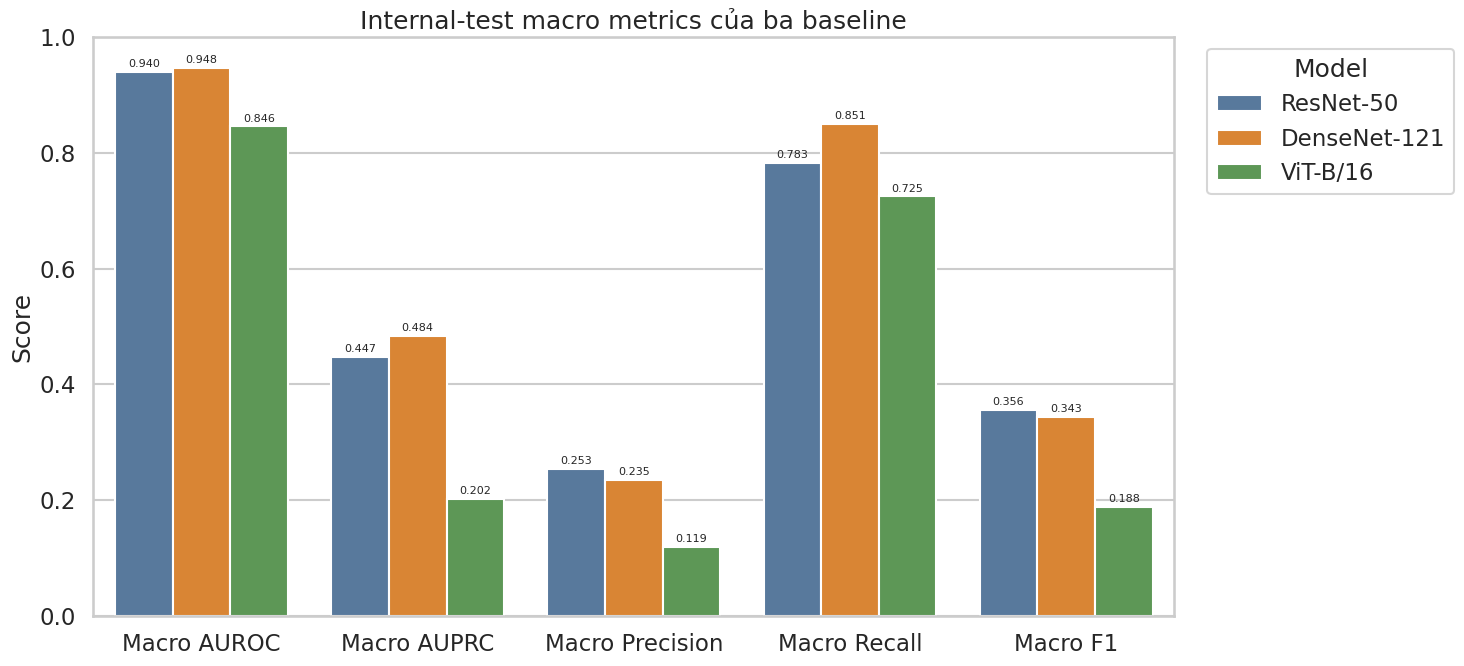

In [12]:
sns.set_theme(style="whitegrid", context="talk")

macro_columns = [
    "Macro AUROC",
    "Macro AUPRC",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
]

macro_long = test_summary_df.melt(
    id_vars="Model",
    value_vars=macro_columns,
    var_name="Metric",
    value_name="Score",
)

fig, ax = plt.subplots(figsize=(15, 7))

sns.barplot(
    data=macro_long,
    x="Metric",
    y="Score",
    hue="Model",
    hue_order=MODEL_ORDER,
    palette=MODEL_COLORS,
    ax=ax,
)

ax.set(
    title="Internal-test macro metrics của ba baseline",
    xlabel="",
    ylabel="Score",
    ylim=(0, 1),
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=8,
        padding=2,
    )

ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "01_macro_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_ROOT / "01_macro_metrics_comparison.pdf",
    bbox_inches="tight",
)

plt.show()

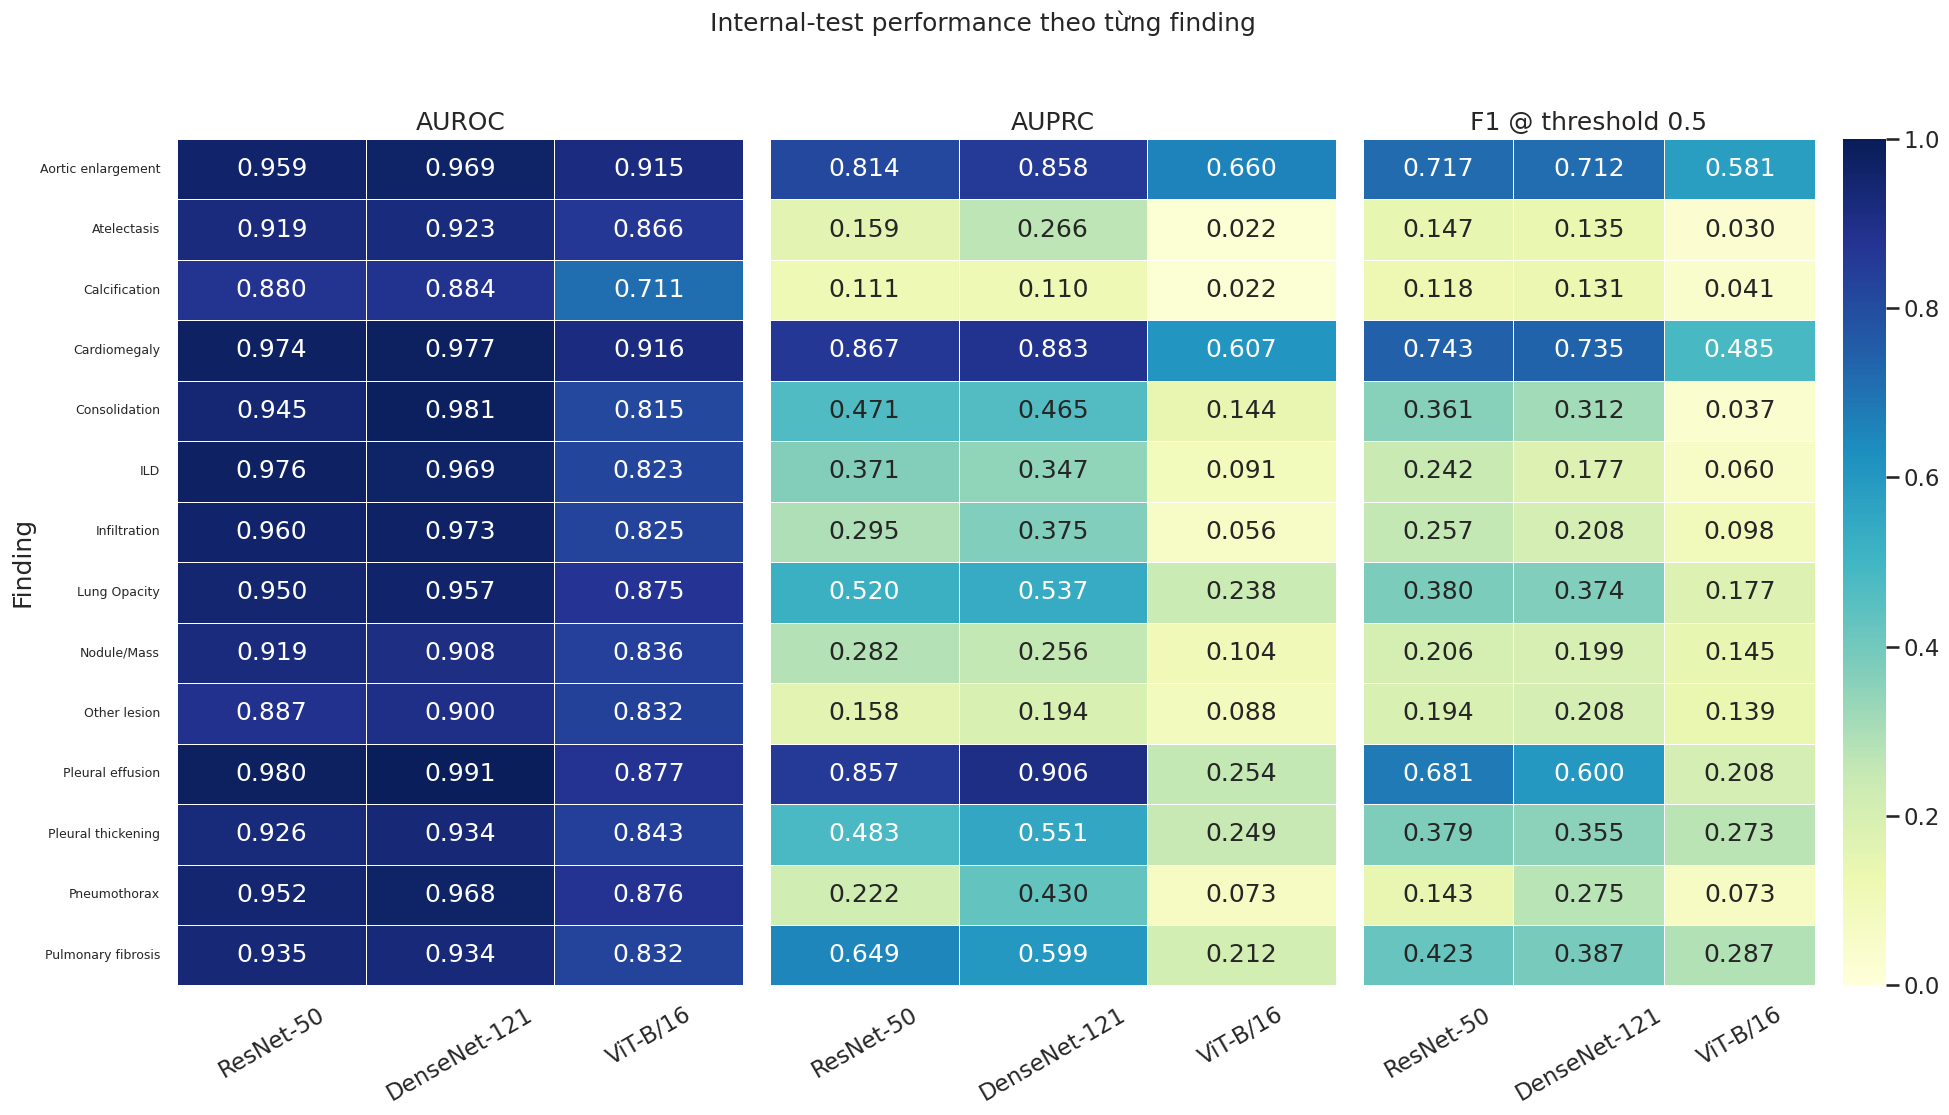

In [13]:
heatmap_metrics = [
    ("auroc", "AUROC"),
    ("average_precision", "AUPRC"),
    ("f1", "F1 @ threshold 0.5"),
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 11),
    sharey=True,
)

for ax, (metric_column, title) in zip(
    axes,
    heatmap_metrics,
):
    matrix = per_class_df.pivot(
        index="finding",
        columns="Model",
        values=metric_column,
    )

    matrix = matrix.reindex(
        index=finding_order,
        columns=MODEL_ORDER,
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        cbar=ax is axes[-1],
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(
        "Finding" if ax is axes[0] else ""
    )
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", labelsize=9)

fig.suptitle(
    "Internal-test performance theo từng finding",
    fontsize=18,
    y=1.02,
)
fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "02_per_class_metrics_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_ROOT / "02_per_class_metrics_heatmap.pdf",
    bbox_inches="tight",
)

plt.show()

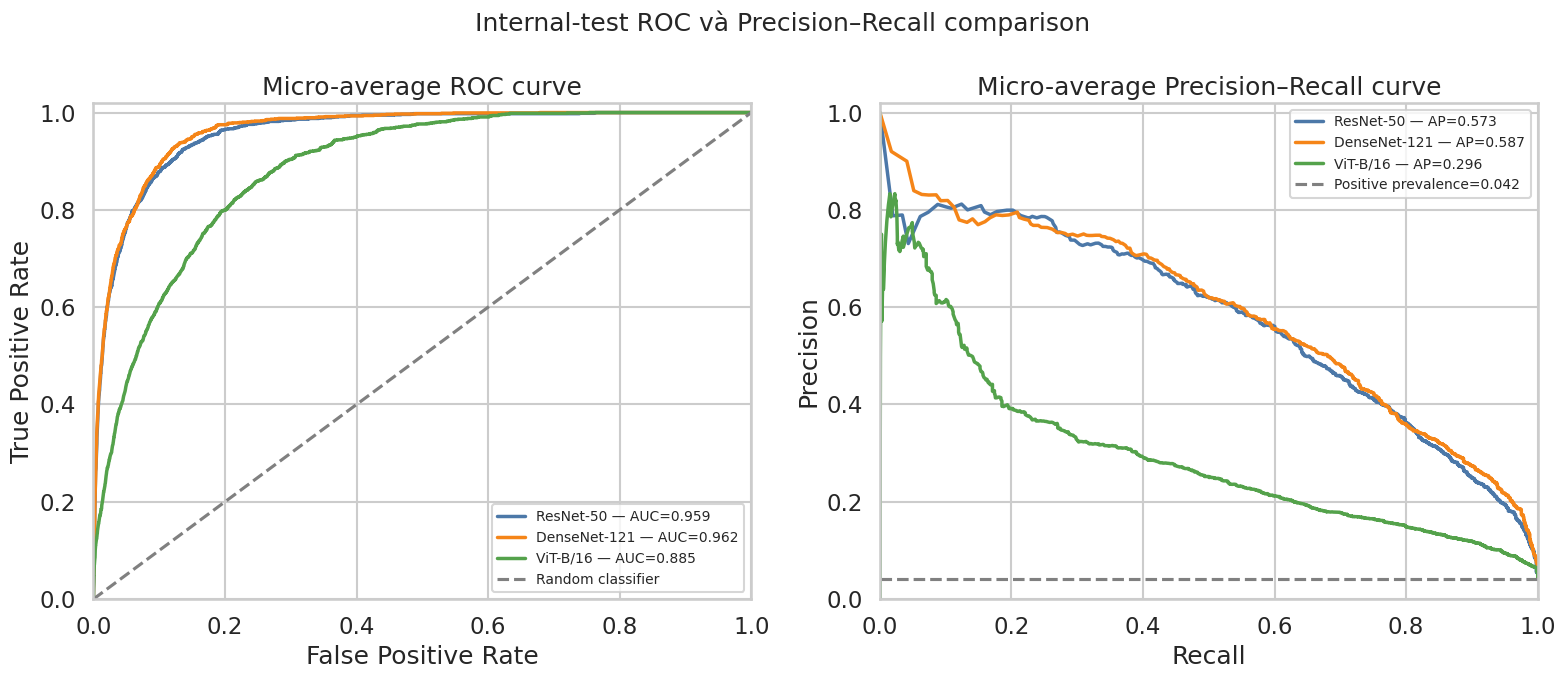

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

positive_prevalence = reference_targets.mean()

for model_label in MODEL_ORDER:
    targets = test_data[model_label]["targets"].ravel()
    probabilities = (
        test_data[model_label]["probabilities"].ravel()
    )

    fpr, tpr, _ = roc_curve(targets, probabilities)
    micro_roc_auc = auc(fpr, tpr)

    precision, recall, _ = precision_recall_curve(
        targets,
        probabilities,
    )
    micro_ap = average_precision_score(
        targets,
        probabilities,
    )

    axes[0].plot(
        fpr,
        tpr,
        color=MODEL_COLORS[model_label],
        linewidth=2.5,
        label=f"{model_label} — AUC={micro_roc_auc:.3f}",
    )

    axes[1].plot(
        recall,
        precision,
        color=MODEL_COLORS[model_label],
        linewidth=2.5,
        label=f"{model_label} — AP={micro_ap:.3f}",
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier",
)
axes[0].set(
    title="Micro-average ROC curve",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[0].legend(fontsize=10)

axes[1].axhline(
    positive_prevalence,
    linestyle="--",
    color="gray",
    label=f"Positive prevalence={positive_prevalence:.3f}",
)
axes[1].set(
    title="Micro-average Precision–Recall curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[1].legend(fontsize=10)

fig.suptitle(
    "Internal-test ROC và Precision–Recall comparison",
    fontsize=18,
)
fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "03_micro_roc_pr_curves.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_ROOT / "03_micro_roc_pr_curves.pdf",
    bbox_inches="tight",
)

plt.show()

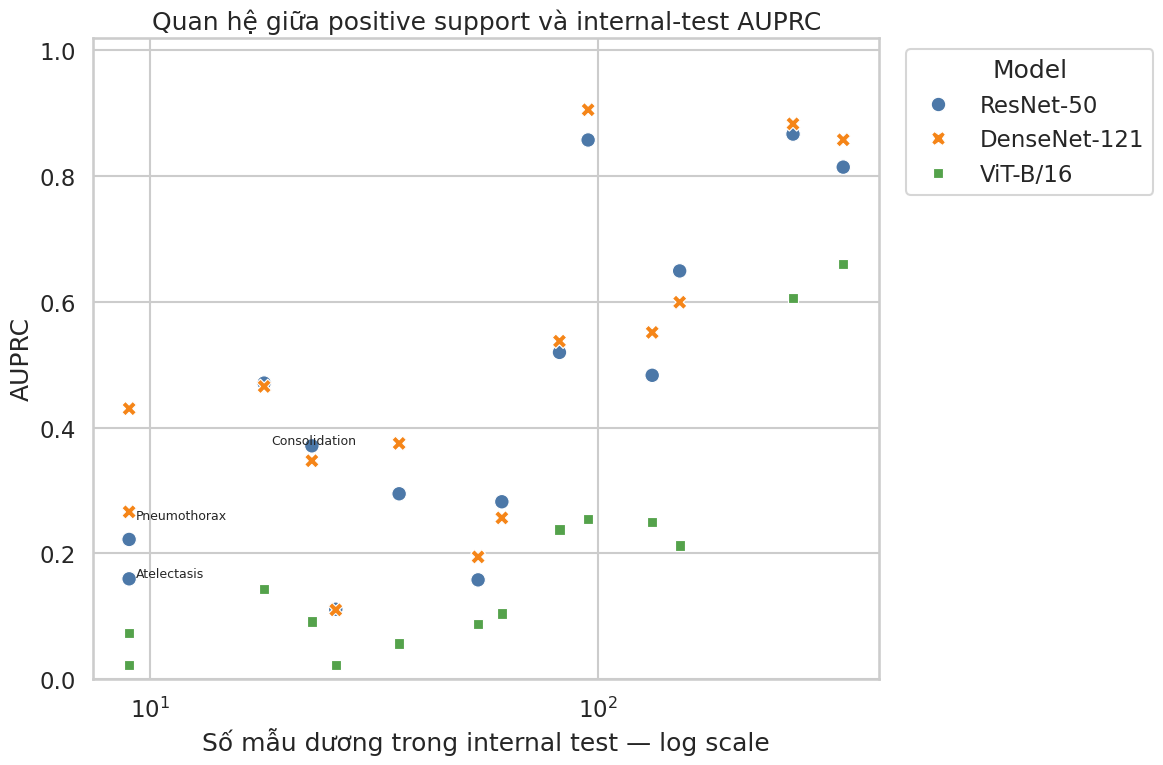

In [15]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=per_class_df,
    x="positive_count",
    y="average_precision",
    hue="Model",
    hue_order=MODEL_ORDER,
    palette=MODEL_COLORS,
    style="Model",
    s=110,
    ax=ax,
)

ax.set_xscale("log")
ax.set(
    title="Quan hệ giữa positive support và internal-test AUPRC",
    xlabel="Số mẫu dương trong internal test — log scale",
    ylabel="AUPRC",
    ylim=(0, 1.02),
)

rare_findings = {
    "Atelectasis",
    "Pneumothorax",
    "Consolidation",
}

annotation_source = (
    per_class_df[
        per_class_df["finding"].isin(rare_findings)
    ]
    .groupby("finding", as_index=False)
    .agg(
        positive_count=("positive_count", "first"),
        average_precision=("average_precision", "mean"),
    )
)

for row in annotation_source.itertuples(index=False):
    ax.annotate(
        row.finding,
        (row.positive_count, row.average_precision),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9,
    )

ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "04_class_support_vs_auprc.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_ROOT / "04_class_support_vs_auprc.pdf",
    bbox_inches="tight",
)

plt.show()

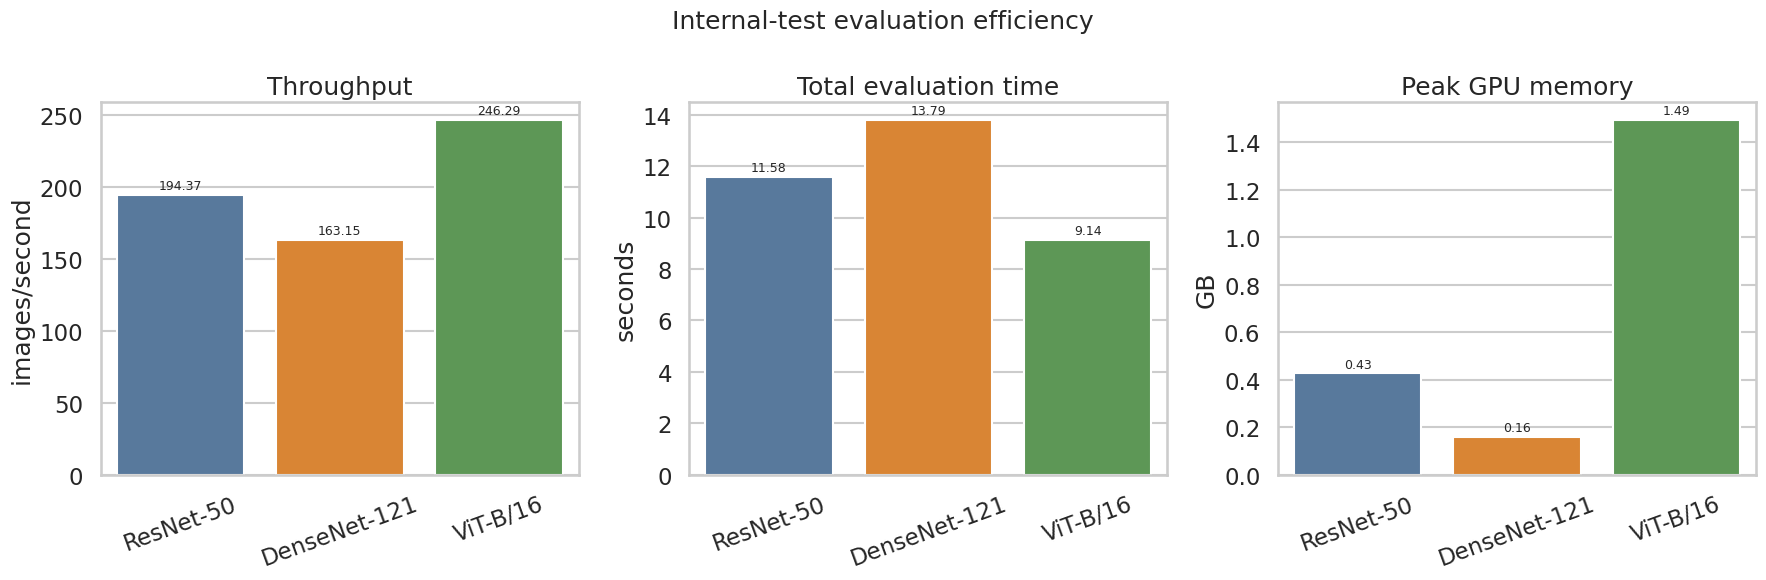

In [16]:
performance_metrics = [
    ("Images/second", "Throughput", "images/second"),
    ("Elapsed seconds", "Total evaluation time", "seconds"),
    (
        "Peak GPU memory (GB)",
        "Peak GPU memory",
        "GB",
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (column, title, ylabel) in zip(
    axes,
    performance_metrics,
):
    sns.barplot(
        data=test_summary_df,
        x="Model",
        y=column,
        order=MODEL_ORDER,
        hue="Model",
        hue_order=MODEL_ORDER,
        palette=MODEL_COLORS,
        legend=False,
        ax=ax,
    )

    ax.set(
        title=title,
        xlabel="",
        ylabel=ylabel,
    )
    ax.tick_params(axis="x", rotation=20)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            fontsize=9,
            padding=2,
        )

fig.suptitle(
    "Internal-test evaluation efficiency",
    fontsize=18,
)
fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "05_evaluation_efficiency.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_ROOT / "05_evaluation_efficiency.pdf",
    bbox_inches="tight",
)

plt.show()

In [17]:
figure_manifest = {
    "split": "test",
    "num_images": EXPECTED_TEST_IMAGES,
    "threshold": EXPECTED_THRESHOLD,
    "split_assignment_sha256": EXPECTED_FINGERPRINT,
    "models": MODEL_ORDER,
    "figures": [
        "01_macro_metrics_comparison.png",
        "02_per_class_metrics_heatmap.png",
        "03_micro_roc_pr_curves.png",
        "04_class_support_vs_auprc.png",
        "05_evaluation_efficiency.png",
    ],
    "source_artifacts": {
        experiment["run_name"]: str(
            RUN_LOG_ROOT / experiment["run_name"] / "test"
        )
        for experiment in EXPERIMENTS
    },
}

(
    FIGURE_ROOT / "figure_manifest.json"
).write_text(
    json.dumps(
        figure_manifest,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

archive_base = RUN_LOG_ROOT / "internal_test_figures"
archive_path = Path(
    shutil.make_archive(
        str(archive_base),
        "zip",
        root_dir=FIGURE_ROOT,
    )
)

print("Figures:", FIGURE_ROOT)
print("Archive:", archive_path)
print("Files:")

for path in sorted(FIGURE_ROOT.iterdir()):
    print("-", path.name)

Figures: /content/drive/MyDrive/DATH_CXR/run_logs/internal_test_figures
Archive: /content/drive/MyDrive/DATH_CXR/run_logs/internal_test_figures.zip
Files:
- 01_macro_metrics_comparison.pdf
- 01_macro_metrics_comparison.png
- 02_per_class_metrics_heatmap.pdf
- 02_per_class_metrics_heatmap.png
- 03_micro_roc_pr_curves.pdf
- 03_micro_roc_pr_curves.png
- 04_class_support_vs_auprc.pdf
- 04_class_support_vs_auprc.png
- 05_evaluation_efficiency.pdf
- 05_evaluation_efficiency.png
- figure_manifest.json
- internal_test_model_summary.csv
- internal_test_per_class_metrics.csv
